In [2]:
import pandas as pd
import numpy as np

#loading the dataset
df = pd.read_csv(
   "C:\\Users\\LENOVO\\OneDrive\\Desktop\\Student-Performance-DNN\\datasets\\student-por.csv", #absolute path to the dataset
    sep=";"
)

print("Dataset loaded successfully!")

Dataset loaded successfully!


#dataset knowledge

In [3]:
df.head(5)


,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,...,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
0,GP,F,18,U,GT3,A,4,4,at_home,teacher,...,4,3,4,1,1,3,4,0,11,11
1,GP,F,17,U,GT3,T,1,1,at_home,other,...,5,3,3,1,1,3,2,9,11,11
2,GP,F,15,U,LE3,T,1,1,at_home,other,...,4,3,2,2,3,3,6,12,13,12
3,GP,F,15,U,GT3,T,4,2,health,services,...,3,2,2,1,1,5,0,14,14,14
4,GP,F,16,U,GT3,T,3,3,other,other,...,4,3,2,1,2,5,0,11,13,13


In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 649 entries, 0 to 648
Data columns (total 33 columns):
 #   Column      Non-Null Count  Dtype
---  ------      --------------  -----
 0   school      649 non-null    str  
 1   sex         649 non-null    str  
 2   age         649 non-null    int64
 3   address     649 non-null    str  
 4   famsize     649 non-null    str  
 5   Pstatus     649 non-null    str  
 6   Medu        649 non-null    int64
 7   Fedu        649 non-null    int64
 8   Mjob        649 non-null    str  
 9   Fjob        649 non-null    str  
 10  reason      649 non-null    str  
 11  guardian    649 non-null    str  
 12  traveltime  649 non-null    int64
 13  studytime   649 non-null    int64
 14  failures    649 non-null    int64
 15  schoolsup   649 non-null    str  
 16  famsup      649 non-null    str  
 17  paid        649 non-null    str  
 18  activities  649 non-null    str  
 19  nursery     649 non-null    str  
 20  higher      649 non-null    str  
 21  inte

In [5]:
print(df.shape)

(649, 33)


In [6]:
df.describe()

,age,Medu,Fedu,traveltime,studytime,failures,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
count,649.000000,649.000000,649.000000,649.000000,649.000000,649.000000,649.000000,649.000000,649.000000,649.000000,649.000000,649.000000,649.000000,649.000000,649.000000,649.000000
mean,16.744222,2.514638,2.306626,1.568567,1.930663,0.221880,3.930663,3.180277,3.184900,1.502311,2.280431,3.536210,3.659476,11.399076,11.570108,11.906009
std,1.218138,1.134552,1.099931,0.748660,0.829510,0.593235,0.955717,1.051093,1.175766,0.924834,1.284380,1.446259,4.640759,2.745265,2.913639,3.230656
min,15.000000,0.000000,0.000000,1.000000,1.000000,0.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,0.000000,0.000000,0.000000,0.000000
25%,16.000000,2.000000,1.000000,1.000000,1.000000,0.000000,4.000000,3.000000,2.000000,1.000000,1.000000,2.000000,0.000000,10.000000,10.000000,10.000000
50%,17.000000,2.000000,2.000000,1.000000,2.000000,0.000000,4.000000,3.000000,3.000000,1.000000,2.000000,4.000000,2.000000,11.000000,11.000000,12.000000
75%,18.000000,4.000000,3.000000,2.000000,2.000000,0.000000,5.000000,4.000000,4.000000,2.000000,3.000000,5.000000,6.000000,13.000000,13.000000,14.000000
max,22.000000,4.000000,4.000000,4.000000,4.000000,3.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,32.000000,19.000000,19.000000,19.000000


In [7]:
print(df.isnull().sum())

school        0
sex           0
age           0
address       0
famsize       0
Pstatus       0
Medu          0
Fedu          0
Mjob          0
Fjob          0
reason        0
guardian      0
traveltime    0
studytime     0
failures      0
schoolsup     0
famsup        0
paid          0
activities    0
nursery       0
higher        0
internet      0
romantic      0
famrel        0
freetime      0
goout         0
Dalc          0
Walc          0
health        0
absences      0
G1            0
G2            0
G3            0
dtype: int64


In [8]:
# x is independent variable whereas y is a dependent variable.
X = df.drop("G3", axis=1)
y = df["G3"]

In [9]:
print("Features:", X.shape)  # target col(G3) removed so it become 32 from 33.
print("Target:", y.shape)    # only the target col is taken is col=0,and total rows 649.

Features: (649, 32)
Target: (649,)


In [10]:
print(df.dtypes)

school          str
sex             str
age           int64
address         str
famsize         str
Pstatus         str
Medu          int64
Fedu          int64
Mjob            str
Fjob            str
reason          str
guardian        str
traveltime    int64
studytime     int64
failures      int64
schoolsup       str
famsup          str
paid            str
activities      str
nursery         str
higher          str
internet        str
romantic        str
famrel        int64
freetime      int64
goout         int64
Dalc          int64
Walc          int64
health        int64
absences      int64
G1            int64
G2            int64
G3            int64
dtype: object


In [11]:
# neural networks takes input as numerical data so the one classified as categorical will be changed to numerical
categorical = df.select_dtypes(include="str").columns
numerical = df.select_dtypes(include="number").columns

print("Categorical columns:")
print(categorical)

print("\nNumerical columns:")
print(numerical)

Categorical columns:
Index(['school', 'sex', 'address', 'famsize', 'Pstatus', 'Mjob', 'Fjob',
       'reason', 'guardian', 'schoolsup', 'famsup', 'paid', 'activities',
       'nursery', 'higher', 'internet', 'romantic'],
      dtype='str')

Numerical columns:
Index(['age', 'Medu', 'Fedu', 'traveltime', 'studytime', 'failures', 'famrel',
       'freetime', 'goout', 'Dalc', 'Walc', 'health', 'absences', 'G1', 'G2',
       'G3'],
      dtype='str')


In [12]:
for col in categorical:
    print(col, ":", df[col].unique())

school : <ArrowStringArray>
['GP', 'MS']
Length: 2, dtype: str
sex : <ArrowStringArray>
['F', 'M']
Length: 2, dtype: str
address : <ArrowStringArray>
['U', 'R']
Length: 2, dtype: str
famsize : <ArrowStringArray>
['GT3', 'LE3']
Length: 2, dtype: str
Pstatus : <ArrowStringArray>
['A', 'T']
Length: 2, dtype: str
Mjob : <ArrowStringArray>
['at_home', 'health', 'other', 'services', 'teacher']
Length: 5, dtype: str
Fjob : <ArrowStringArray>
['teacher', 'other', 'services', 'health', 'at_home']
Length: 5, dtype: str
reason : <ArrowStringArray>
['course', 'other', 'home', 'reputation']
Length: 4, dtype: str
guardian : <ArrowStringArray>
['mother', 'father', 'other']
Length: 3, dtype: str
schoolsup : <ArrowStringArray>
['yes', 'no']
Length: 2, dtype: str
famsup : <ArrowStringArray>
['no', 'yes']
Length: 2, dtype: str
paid : <ArrowStringArray>
['no', 'yes']
Length: 2, dtype: str
activities : <ArrowStringArray>
['no', 'yes']
Length: 2, dtype: str
nursery : <ArrowStringArray>
['yes', 'no']
Length:

As we understood the input features , now we will learn about the output feature.

In [13]:
print(df["G3"].value_counts().sort_index())

G3
0      15
1       1
5       1
6       3
7      10
8      35
9      35
10     97
11    104
12     72
13     82
14     63
15     49
16     36
17     29
18     15
19      2
Name: count, dtype: int64


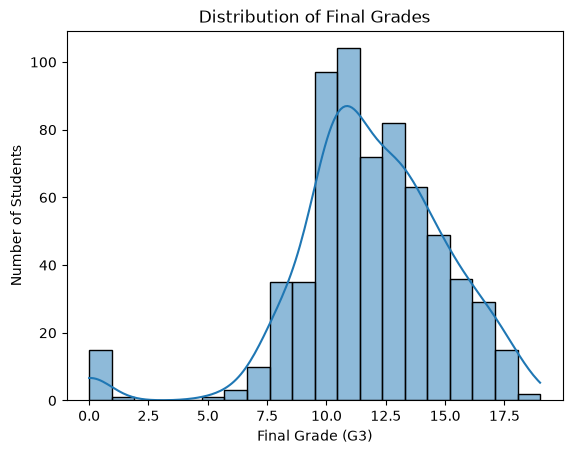

In [14]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.histplot(df["G3"], bins=20, kde=True)

plt.title("Distribution of Final Grades")
plt.xlabel("Final Grade (G3)")
plt.ylabel("Number of Students")

plt.show()

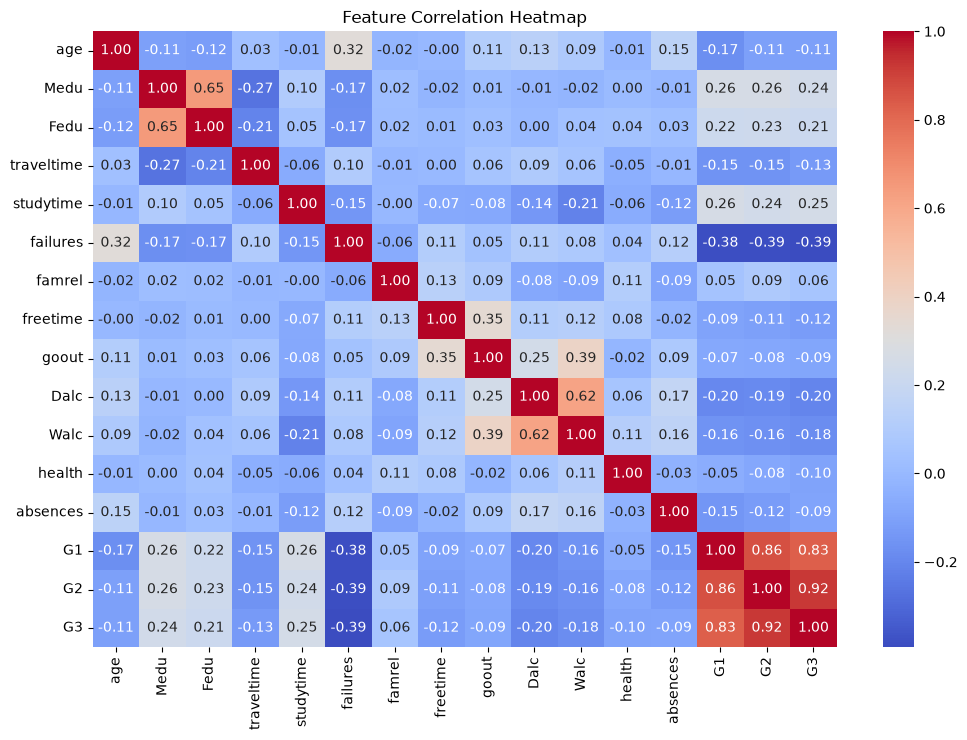

In [15]:
# corr tells us which feature has more relationship with the target output (g3)
correlation = df.select_dtypes(include="number").corr()

plt.figure(figsize=(12, 8))
sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)
plt.title("Feature Correlation Heatmap")
plt.show()

In [16]:
# feature selection using corr -> g2 hs more specified relationship with g3 which is our target output 
g3_correlation = correlation["G3"].sort_values(ascending=False)
print(g3_correlation)

G3            1.000000
G2            0.918548
G1            0.826387
studytime     0.249789
Medu          0.240151
Fedu          0.211800
famrel        0.063361
goout        -0.087641
absences     -0.091379
health       -0.098851
age          -0.106505
freetime     -0.122705
traveltime   -0.127173
Walc         -0.176619
Dalc         -0.204719
failures     -0.393316
Name: G3, dtype: float64


In [17]:
# checking how many duplicates are present
print("Duplicate rows:", df.duplicated().sum())

Duplicate rows: 0


In [18]:
print("Total Records:", df.shape[0])
print("Total Features:", df.shape[1])
print("Missing Values:", df.isnull().sum().sum())
print("Duplicate Records:", df.duplicated().sum())
print("Target Column:", "G3")

Total Records: 649
Total Features: 33
Missing Values: 0
Duplicate Records: 0
Target Column: G3


now comes the preprocessing part ->here we will separate the input features and target features

In [19]:
X = df.drop("G3", axis=1)
y = df["G3"]
print("Input Features:", X.shape)
print("Target:", y.shape)

Input Features: (649, 32)
Target: (649,)


In [20]:
# test_size=0.2: 20% data is reserved for testing.
# Remaining 80% is used to train the model.
# random_state=42: Keeps the split consistent whenever you run the code.

from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (519, 32)
Testing data: (130, 32)


In [21]:
# finding which cols are numerical and which are categorical so that we can convert categorical into numerical using One hot encoding technique

categorical_cols = X_train.select_dtypes(include="str").columns.tolist()

numerical_cols = X_train.select_dtypes(include="number").columns.tolist()

print("Categorical Columns:", categorical_cols)
print("\nNumerical Columns:", numerical_cols)

Categorical Columns: ['school', 'sex', 'address', 'famsize', 'Pstatus', 'Mjob', 'Fjob', 'reason', 'guardian', 'schoolsup', 'famsup', 'paid', 'activities', 'nursery', 'higher', 'internet', 'romantic']

Numerical Columns: ['age', 'Medu', 'Fedu', 'traveltime', 'studytime', 'failures', 'famrel', 'freetime', 'goout', 'Dalc', 'Walc', 'health', 'absences', 'G1', 'G2']


one hot encoding

In [22]:
# OneHotEncoder: Converts text categories into numerical columns. For example, sex becomes separate binary columns
# StandardScaler: Scales numerical values so features have comparable scales.
# ColumnTransformer: Applies the correct preprocessing method to each column type.
# handle_unknown="ignore": Handles categories that weren't present in training data.

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

preprocessor = ColumnTransformer(
    transformers=[
        ("categorical", OneHotEncoder(handle_unknown="ignore"), categorical_cols),
        ("numerical", StandardScaler(), numerical_cols)
    ]
)

In [23]:
# now the col have increased because we changed the categorical cols were converted in numerical cols.

X_train_processed = preprocessor.fit_transform(X_train)
X_test_processed = preprocessor.transform(X_test)

print("Training data shape:", X_train_processed.shape)
print("Testing data shape:", X_test_processed.shape)

Training data shape: (519, 58)
Testing data shape: (130, 58)


now here comes the preprocessing part - here we will convert the training and testing data in arrays.

In [24]:
import numpy as np

X_train_processed = np.array(X_train_processed, dtype=np.float32)
X_test_processed = np.array(X_test_processed, dtype=np.float32)

y_train = np.array(y_train, dtype=np.float32)
y_test = np.array(y_test, dtype=np.float32)

print("X_train:", X_train_processed.shape)
print("X_test:", X_test_processed.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

X_train: (519, 58)
X_test: (130, 58)
y_train: (519,)
y_test: (130,)


In [25]:
print("Training samples:", X_train_processed.shape[0])
print("Testing samples:", X_test_processed.shape[0])
print("Input features after encoding:", X_train_processed.shape[1])

print("Missing values:", np.isnan(X_train_processed).sum())
print("Infinite values:", np.isinf(X_train_processed).sum())

Training samples: 519
Testing samples: 130
Input features after encoding: 58
Missing values: 0
Infinite values: 0


In [26]:
y_train = y_train.reshape(-1, 1)
y_test = y_test.reshape(-1, 1)

print("Training target:", y_train.shape)
print("Testing target:", y_test.shape)

Training target: (519, 1)
Testing target: (130, 1)


In [27]:
import joblib
import os

os.makedirs("models", exist_ok=True)

joblib.dump(preprocessor, "models/preprocessor.pkl")

['models/preprocessor.pkl']

In [28]:
np.save("models/X_train.npy", X_train_processed)
np.save("models/X_test.npy", X_test_processed)
np.save("models/y_train.npy", y_train)
np.save("models/y_test.npy", y_test)

now we will find which model to use - regression or classification

In [29]:
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
import matplotlib.pyplot as plt

print("TensorFlow:", tf.__version__)

TensorFlow: 2.21.0


In [30]:
input_features = X_train_processed.shape[1]
print("Number of input features:", input_features)

Number of input features: 58


neural network -> relu 64,32,16 neurons

In [31]:
model = keras.Sequential([
    layers.Input(shape=(input_features,)),
    layers.Dense(64, activation="relu"),
    layers.Dense(32, activation="relu"),
    layers.Dense(16, activation="relu"),
    layers.Dense(1, activation="linear")
])

In [32]:
model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss="mean_squared_error",
    metrics=["mean_absolute_error"]
)

In [33]:
early_stop = keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=15,
    restore_best_weights=True
)

In [34]:
history = model.fit(
    X_train_processed,
    y_train,
    validation_split=0.2,
    epochs=200,
    batch_size=16,
    callbacks=[early_stop],
    verbose=1
)

Epoch 1/200
26/26 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 115.4156 - mean_absolute_error: 10.2420 - val_loss: 76.4986 - val_mean_absolute_error: 8.4655
Epoch 2/200
26/26 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 32.8120 - mean_absolute_error: 4.7702 - val_loss: 5.0901 - val_mean_absolute_error: 1.6874
Epoch 3/200
26/26 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 5.8476 - mean_absolute_error: 1.6790 - val_loss: 2.5855 - val_mean_absolute_error: 1.2151
Epoch 4/200
26/26 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 3.5358 - mean_absolute_error: 1.3112 - val_loss: 2.0971 - val_mean_absolute_error: 1.0915
Epoch 5/200
26/26 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 2.8636 - mean_absolute_error: 1.1386 - val_loss: 1.7160 - val_mean_absolute_error: 0.9882
Epoch 6/200
26/26 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 2.5119 - mean_absolute_error: 1.0588 - val_loss: 1.5559 - val_mean_absolute_error: 0.9280
Epoch 7/200
26/26 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 2.2584 - mean_absolute_error: 0.9841 - val

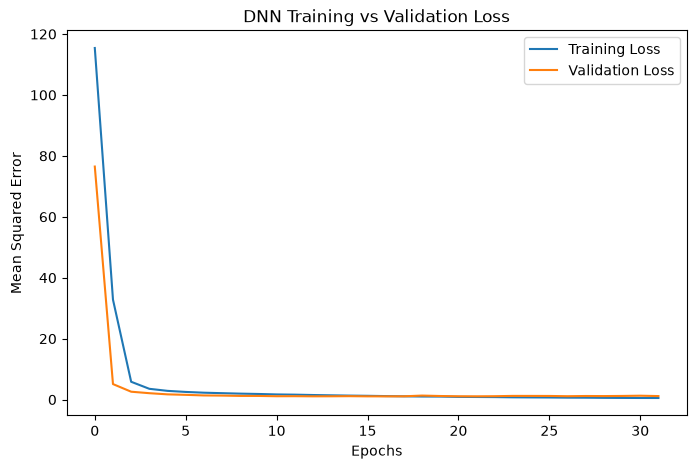

In [35]:
plt.figure(figsize=(8, 5))

plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")

plt.title("DNN Training vs Validation Loss")
plt.xlabel("Epochs")
plt.ylabel("Mean Squared Error")
plt.legend()
plt.show()

In [36]:
test_loss, test_mae = model.evaluate(
    X_test_processed,
    y_test,
    verbose=0
)

print("Test Loss:", test_loss)
print("Test MAE:", test_mae)

Test Loss: 1.7197144031524658
Test MAE: 0.8233891725540161


In [37]:
predictions = model.predict(X_test_processed)

print("Actual Grades:", y_test[:10].flatten())
print("Predicted Grades:", predictions[:10].flatten())

5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step 
Actual Grades: [19. 12. 18. 11. 11. 17. 18.  8. 10. 11.]
Predicted Grades: [18.477524 11.827371 18.427399 11.091563 12.34361  16.497658 17.814028
  9.945548 10.827611 11.05713 ]


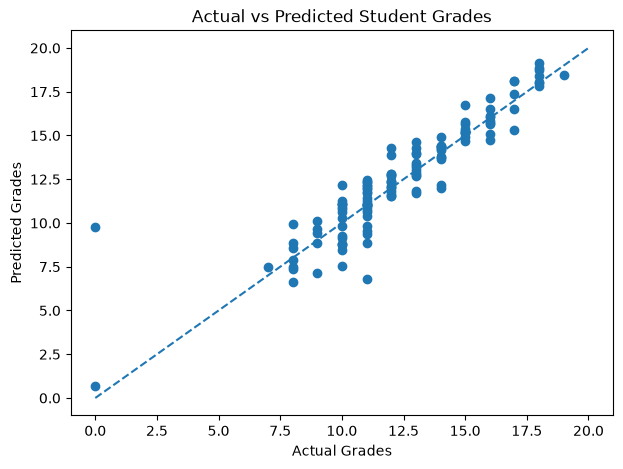

In [38]:
plt.figure(figsize=(7, 5))

plt.scatter(y_test.flatten(), predictions.flatten())

plt.plot([0, 20], [0, 20], linestyle="--")

plt.xlabel("Actual Grades")
plt.ylabel("Predicted Grades")
plt.title("Actual vs Predicted Student Grades")

plt.show()


In [39]:
import os

os.makedirs("models", exist_ok=True)

model.save("models/student_performance_dnn.keras")

phase3

In [40]:
baseline_loss, baseline_mae = model.evaluate(
    X_test_processed,
    y_test,
    verbose=0
)

print("Baseline Test Loss:", baseline_loss)
print("Baseline Test MAE:", baseline_mae)

Baseline Test Loss: 1.7197144031524658
Baseline Test MAE: 0.8233891725540161


In [ ]:
def build_model(learning_rate=0.001, dropout_rate=0.2):

    model = keras.Sequential([
        layers.Input(shape=(input_features,)),

        layers.Dense(64, activation="relu"),
        layers.Dropout(dropout_rate),

        layers.Dense(32, activation="relu"),
        layers.Dropout(dropout_rate),

        layers.Dense(16, activation="relu"),

        layers.Dense(1, activation="linear")
    ])

    model.compile(
        optimizer=keras.optimizers.Adam(
            learning_rate=learning_rate
        ),
        loss="mean_squared_error",
        metrics=["mean_absolute_error"]
    )

    return model

In [42]:
optimized_model = build_model(
    learning_rate=0.001,
    dropout_rate=0.2
)

early_stop = keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=15,
    restore_best_weights=True
)

optimized_history = optimized_model.fit(
    X_train_processed,
    y_train,
    validation_split=0.2,
    epochs=200,
    batch_size=16,
    callbacks=[early_stop],
    verbose=1
)

Epoch 1/200
26/26 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 148.7756 - mean_absolute_error: 11.7233 - val_loss: 136.8350 - val_mean_absolute_error: 11.3824
Epoch 2/200
26/26 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 102.8752 - mean_absolute_error: 9.5765 - val_loss: 55.8198 - val_mean_absolute_error: 6.9943
Epoch 3/200
26/26 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 27.0107 - mean_absolute_error: 4.1208 - val_loss: 7.4844 - val_mean_absolute_error: 2.1298
Epoch 4/200
26/26 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 13.0946 - mean_absolute_error: 2.7399 - val_loss: 4.1947 - val_mean_absolute_error: 1.5869
Epoch 5/200
26/26 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 10.1967 - mean_absolute_error: 2.4662 - val_loss: 2.6437 - val_mean_absolute_error: 1.2335
Epoch 6/200
26/26 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 8.7937 - mean_absolute_error: 2.2936 - val_loss: 2.2154 - val_mean_absolute_error: 1.1114
Epoch 7/200
26/26 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 7.6686 - mean_absolute_error: 2.190

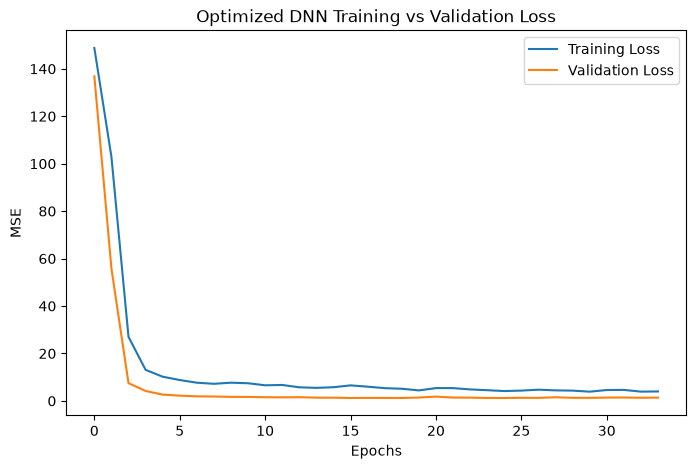

In [43]:
plt.figure(figsize=(8, 5))

plt.plot(
    optimized_history.history["loss"],
    label="Training Loss"
)

plt.plot(
    optimized_history.history["val_loss"],
    label="Validation Loss"
)

plt.title("Optimized DNN Training vs Validation Loss")
plt.xlabel("Epochs")
plt.ylabel("MSE")
plt.legend()
plt.show()

In [44]:
optimized_loss, optimized_mae = optimized_model.evaluate(
    X_test_processed,
    y_test,
    verbose=0
)

print("Optimized Test Loss:", optimized_loss)
print("Optimized Test MAE:", optimized_mae)

Optimized Test Loss: 1.8433932065963745
Optimized Test MAE: 0.881797194480896


In [45]:
print("ORIGINAL DNN")
print("Test Loss:", baseline_loss)
print("Test MAE:", baseline_mae)

print("\nOPTIMIZED DNN")
print("Test Loss:", optimized_loss)
print("Test MAE:", optimized_mae)

ORIGINAL DNN
Test Loss: 1.7197144031524658
Test MAE: 0.8233891725540161

OPTIMIZED DNN
Test Loss: 1.8433932065963745
Test MAE: 0.881797194480896


In [46]:
learning_rates = [0.01, 0.001, 0.0001]

lr_results = []

for lr in learning_rates:

    temp_model = build_model(
        learning_rate=lr,
        dropout_rate=0.2
    )

    temp_model.fit(
        X_train_processed,
        y_train,
        validation_split=0.2,
        epochs=100,
        batch_size=16,
        callbacks=[early_stop],
        verbose=0
    )

    loss, mae = temp_model.evaluate(
        X_test_processed,
        y_test,
        verbose=0
    )

    lr_results.append((lr, loss, mae))

for result in lr_results:
    print(
        "Learning Rate:", result[0],
        "| Loss:", result[1],
        "| MAE:", result[2]
    )

Learning Rate: 0.01 | Loss: 2.113632917404175 | MAE: 1.0327564477920532
Learning Rate: 0.001 | Loss: 1.5609521865844727 | MAE: 0.8570899963378906
Learning Rate: 0.0001 | Loss: 1.7791377305984497 | MAE: 0.8761736154556274


In [47]:
dropout_rates = [0.1, 0.2, 0.3]

dropout_results = []

for rate in dropout_rates:

    temp_model = build_model(
        learning_rate=0.001,
        dropout_rate=rate
    )

    temp_model.fit(
        X_train_processed,
        y_train,
        validation_split=0.2,
        epochs=100,
        batch_size=16,
        callbacks=[early_stop],
        verbose=0
    )

    loss, mae = temp_model.evaluate(
        X_test_processed,
        y_test,
        verbose=0
    )

    dropout_results.append((rate, loss, mae))

for result in dropout_results:
    print(
        "Dropout:", result[0],
        "| Loss:", result[1],
        "| MAE:", result[2]
    )

Dropout: 0.1 | Loss: 1.7136675119400024 | MAE: 0.8302524089813232
Dropout: 0.2 | Loss: 2.0440049171447754 | MAE: 0.9741314649581909
Dropout: 0.3 | Loss: 2.047394037246704 | MAE: 0.9825796484947205


In [48]:
learning_rates = [0.01, 0.001, 0.0001]
batch_sizes = [8, 16, 32]
dropout_rates = [0.1, 0.2, 0.3]

results = []

for lr in learning_rates:
    for batch in batch_sizes:
        for dropout in dropout_rates:

            temp_model = build_model(
                learning_rate=lr,
                dropout_rate=dropout
            )

            callback = keras.callbacks.EarlyStopping(
                monitor="val_loss",
                patience=15,
                restore_best_weights=True
            )

            history_temp = temp_model.fit(
                X_train_processed,
                y_train,
                validation_split=0.2,
                epochs=100,
                batch_size=batch,
                callbacks=[callback],
                verbose=0
            )

            best_val_mae = min(
                history_temp.history["val_mean_absolute_error"]
            )

            results.append({
                "learning_rate": lr,
                "batch_size": batch,
                "dropout": dropout,
                "validation_mae": best_val_mae
            })

print("Experiments completed:", len(results))

Experiments completed: 27


In [49]:
results_df = pd.DataFrame(results)

results_df = results_df.sort_values(
    by="validation_mae"
)

print(results_df.head(10))

    learning_rate  batch_size  dropout  validation_mae
12         0.0010          16      0.1        0.744750
15         0.0010          32      0.1        0.757707
19         0.0001           8      0.2        0.777582
9          0.0010           8      0.1        0.779120
4          0.0100          16      0.2        0.781460
13         0.0010          16      0.2        0.813718
6          0.0100          32      0.1        0.816717
3          0.0100          16      0.1        0.821410
18         0.0001           8      0.1        0.821460
21         0.0001          16      0.1        0.826074


In [50]:
best = results_df.iloc[0]

optimized_model = build_model(
    learning_rate=best["learning_rate"],
    dropout_rate=best["dropout"]
)

early_stop = keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=15,
    restore_best_weights=True
)

optimized_history = optimized_model.fit(
    X_train_processed,
    y_train,
    validation_split=0.2,
    epochs=200,
    batch_size=int(best["batch_size"]),
    callbacks=[early_stop],
    verbose=1
)

Epoch 1/200
26/26 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - loss: 112.7285 - mean_absolute_error: 10.0820 - val_loss: 73.4286 - val_mean_absolute_error: 8.1503
Epoch 2/200
26/26 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 33.0571 - mean_absolute_error: 4.8112 - val_loss: 6.9215 - val_mean_absolute_error: 1.9804
Epoch 3/200
26/26 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 10.3001 - mean_absolute_error: 2.2931 - val_loss: 3.9386 - val_mean_absolute_error: 1.5207
Epoch 4/200
26/26 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 6.8825 - mean_absolute_error: 1.9591 - val_loss: 2.6180 - val_mean_absolute_error: 1.1493
Epoch 5/200
26/26 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 6.0682 - mean_absolute_error: 1.8596 - val_loss: 2.3241 - val_mean_absolute_error: 1.0969
Epoch 6/200
26/26 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 5.3067 - mean_absolute_error: 1.7284 - val_loss: 2.0077 - val_mean_absolute_error: 1.0247
Epoch 7/200
26/26 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 5.0340 - mean_absolute_error: 1.6463 - va

In [51]:
optimized_loss, optimized_mae = optimized_model.evaluate(
    X_test_processed,
    y_test,
    verbose=0
)

print("Final Test Loss:", optimized_loss)
print("Final Test MAE:", optimized_mae)

Final Test Loss: 1.777069330215454
Final Test MAE: 0.8258067965507507


In [52]:
comparison = pd.DataFrame({
    "Model": ["Original DNN", "Optimized DNN"],
    "Test Loss": [baseline_loss, optimized_loss],
    "Test MAE": [baseline_mae, optimized_mae]
})

print(comparison)

           Model  Test Loss  Test MAE
0   Original DNN   1.719714  0.823389
1  Optimized DNN   1.777069  0.825807


In [53]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [54]:
rf_model = RandomForestRegressor(
    n_estimators=100,
    max_depth=None,
    random_state=42,
    n_jobs=-1
)

In [55]:
rf_model.fit(
    X_train_processed,
    y_train.ravel()
)

,"n_jobs n_jobs: int, default=NoneThe number of jobs to run in parallel. :meth:`fit`, :meth:`predict`,:meth:`decision_path` and :meth:`apply` are all parallelized over thetrees. ``None`` means 1 unless in a :obj:`joblib.parallel_backend`context. ``-1`` means using all processors. See :term:`Glossary<n_jobs>` for more details.",-1
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""squared_error"", ""absolute_error"", ""poisson""}, default=""squared_error""The function to measure the quality of a split. Supported criteriaare ""squared_error"" for the mean squared error, which is equal tovariance reduction as feature selection criterion and minimizes the L2loss using the mean of each terminal node, ""absolute_error"" for the meanabsolute error, which minimizes the L1 loss using the median of each terminalnode, and ""poisson"" which uses reduction in Poisson deviance to find splits,also using the mean of each terminal node... versionadded:: 0.18 Mean Absolute Error (MAE) criterion... versionadded:: 1.0 Poisson criterion... versionchanged:: 1.9 Criterion `""friedman_mse""` was deprecated.",'squared_error'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=1.0The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None or 1.0, then `max_features=n_features`... note:: The default of 1.0 is equivalent to bagged trees and more randomness can be achieved by setting smaller values, e.g. 0.3... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to 1.0.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",1.0
,"m

In [56]:
print("X_train_processed" in globals())
print("X_train" in globals())
print("preprocessor" in globals())

True
True
True


In [57]:
rf_predictions = rf_model.predict(X_test_processed)

print("Actual Grades:", y_test[:10])
print("Predicted Grades:", rf_predictions[:10])

print("Prediction Shape:", rf_predictions.shape)

Actual Grades: [[19.]
 [12.]
 [18.]
 [11.]
 [11.]
 [17.]
 [18.]
 [ 8.]
 [10.]
 [11.]]
Predicted Grades: [17.23 11.05 17.27 11.02 11.19 16.33 17.49  9.92 10.32 10.38]
Prediction Shape: (130,)


In [58]:
rf_mae = mean_absolute_error(y_test, rf_predictions)

rf_mse = mean_squared_error(y_test, rf_predictions)

rf_rmse = np.sqrt(rf_mse)

rf_r2 = r2_score(y_test, rf_predictions)

print("Random Forest Performance")
print("--------------------------")
print("MAE:", rf_mae)
print("MSE:", rf_mse)
print("RMSE:", rf_rmse)
print("R2 Score:", rf_r2)

Random Forest Performance
--------------------------
MAE: 0.7472307692307693
MSE: 1.544804615384615
RMSE: 1.242901691761909
R2 Score: 0.8415863813985097


In [59]:
from tensorflow import keras

optimized_model = keras.models.load_model(
    "models/student_performance_dnn.keras"
)

print("DNN model loaded successfully!")

DNN model loaded successfully!


In [60]:
import os

print("Current directory:", os.getcwd())
print("Models folder exists:", os.path.exists("models"))

if os.path.exists("models"):
    print("Files:", os.listdir("models"))

Current directory: c:\Users\LENOVO\OneDrive\Desktop\Student-Performance-DNN\notebooks
Models folder exists: True
Files: ['preprocessor.pkl', 'student_performance_dnn.keras', 'X_test.npy', 'X_train.npy', 'y_test.npy', 'y_train.npy']


In [61]:
dnn_predictions = optimized_model.predict(
    X_test_processed
).flatten()

print("Actual Grades:", y_test[:10])
print("DNN Predictions:", dnn_predictions[:10])

5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step 
Actual Grades: [[19.]
 [12.]
 [18.]
 [11.]
 [11.]
 [17.]
 [18.]
 [ 8.]
 [10.]
 [11.]]
DNN Predictions: [18.477524 11.827371 18.427399 11.091563 12.34361  16.497658 17.814028
  9.945548 10.827611 11.05713 ]


In [62]:
dnn_mae = mean_absolute_error(y_test, dnn_predictions)
dnn_mse = mean_squared_error(y_test, dnn_predictions)
dnn_rmse = np.sqrt(dnn_mse)
dnn_r2 = r2_score(y_test, dnn_predictions)

print("DNN MAE:", dnn_mae)
print("DNN MSE:", dnn_mse)
print("DNN RMSE:", dnn_rmse)
print("DNN R2:", dnn_r2)

DNN MAE: 0.8233891725540161
DNN MSE: 1.7197144031524658
DNN RMSE: 1.3113788175628223
DNN R2: 0.8236501216888428


In [63]:
comparison = pd.DataFrame({
    "Model": ["Original DNN", "Random Forest"],
    "MAE": [dnn_mae, rf_mae],
    "MSE": [dnn_mse, rf_mse],
    "RMSE": [dnn_rmse, rf_rmse],
    "R2 Score": [dnn_r2, rf_r2]
})

print(comparison)

           Model       MAE       MSE      RMSE  R2 Score
0   Original DNN  0.823389  1.719714  1.311379  0.823650
1  Random Forest  0.747231  1.544805  1.242902  0.841586


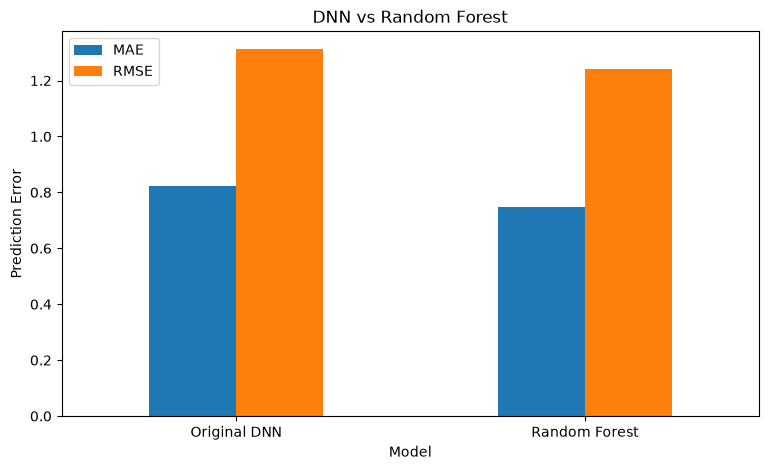

In [64]:
comparison.set_index("Model")[["MAE", "RMSE"]].plot(
    kind="bar",
    figsize=(9, 5)
)

plt.title("DNN vs Random Forest")
plt.ylabel("Prediction Error")
plt.xticks(rotation=0)
plt.show()

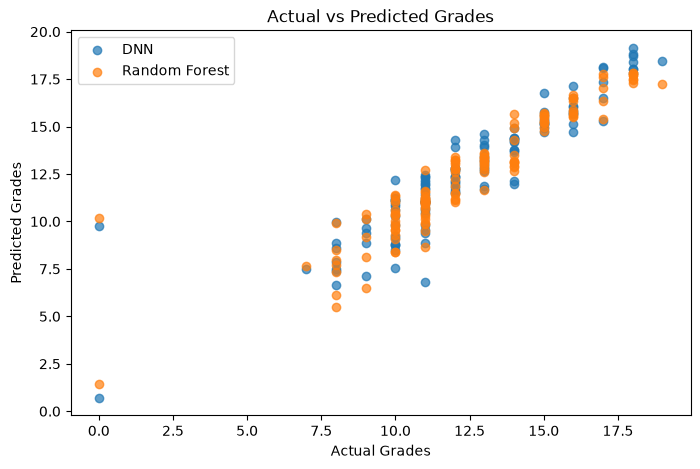

In [65]:
plt.figure(figsize=(8, 5))

plt.scatter(y_test, dnn_predictions, label="DNN", alpha=0.7)
plt.scatter(y_test, rf_predictions, label="Random Forest", alpha=0.7)

plt.xlabel("Actual Grades")
plt.ylabel("Predicted Grades")
plt.title("Actual vs Predicted Grades")
plt.legend()
plt.show()

In [66]:
if dnn_mae < rf_mae:
    print("DNN performs better based on MAE")
elif rf_mae < dnn_mae:
    print("Random Forest performs better based on MAE")
else:
    print("Both models have equal MAE")

Random Forest performs better based on MAE


In [67]:
import joblib
import os

os.makedirs("../models", exist_ok=True)

joblib.dump(
    rf_model,
    "../models/random_forest_model.pkl"
)

print("Random Forest saved successfully!")

Random Forest saved successfully!


In [68]:
import os

print("Current folder:", os.getcwd())
print("Available folders:", os.listdir(".."))
print("Model files:", os.listdir("models"))

Current folder: c:\Users\LENOVO\OneDrive\Desktop\Student-Performance-DNN\notebooks
Available folders: ['app', 'datasets', 'models', 'notebooks', 'requirements.txt']
Model files: ['preprocessor.pkl', 'student_performance_dnn.keras', 'X_test.npy', 'X_train.npy', 'y_test.npy', 'y_train.npy']


In [69]:
import streamlit as st

print("Streamlit version:", st.__version__)

Streamlit version: 1.67.0


In [70]:
print(X_train_processed.shape[1])

58


In [71]:
print("MAE:", dnn_mae)
print("MSE:", dnn_mse)
print("RMSE:", dnn_rmse)
print("R2 Score:", dnn_r2)
print("R2 Percentage:", dnn_r2 * 100, "%")

MAE: 0.8233891725540161
MSE: 1.7197144031524658
RMSE: 1.3113788175628223
R2 Score: 0.8236501216888428
R2 Percentage: 82.36501216888428 %
